# Decision Trees / Classifier

**Type:** Guided machine-learning practice notebook (course-based study).  
**Purpose:** Explore the dataset and the modeling/preprocessing operations illustrated in the code below.  
**Data in this folder:** `13-car_evaluation.csv`.  
**Methods referenced:** `DecisionTreeClassifier`, `Pipeline`, `ColumnTransformer`.

> **Reproducibility note:** Run cells sequentially from this notebook’s folder. Outputs are historical study results, not independently validated benchmarks. The data files were supplied with the original archive; see `DATA_SOURCES.md` at the repository root for provenance checks.


In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("13-car_evaluation.csv")

In [3]:
df

,vhigh,vhigh.1,2,2.1,small,low,unacc
0,vhigh,vhigh,2,2,small,med,unacc
1,vhigh,vhigh,2,2,small,high,unacc
2,vhigh,vhigh,2,2,med,low,unacc
3,vhigh,vhigh,2,2,med,med,unacc
4,vhigh,vhigh,2,2,med,high,unacc
...,...,...,...,...,...,...,...
1722,low,low,5more,more,med,med,good
1723,low,low,5more,more,med,high,vgood
1724,low,low,5more,more,big,low,unacc
1725,low,low,5more,more,big,med,good


In [4]:
columns = ["buying", "maint", "doors", "persons", "lug_boot", "safety", "class"]

In [5]:
df.columns = columns

In [6]:
df

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,med,unacc
1,vhigh,vhigh,2,2,small,high,unacc
2,vhigh,vhigh,2,2,med,low,unacc
3,vhigh,vhigh,2,2,med,med,unacc
4,vhigh,vhigh,2,2,med,high,unacc
...,...,...,...,...,...,...,...
1722,low,low,5more,more,med,med,good
1723,low,low,5more,more,med,high,vgood
1724,low,low,5more,more,big,low,unacc
1725,low,low,5more,more,big,med,good


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1727 entries, 0 to 1726
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1727 non-null   object
 1   maint     1727 non-null   object
 2   doors     1727 non-null   object
 3   persons   1727 non-null   object
 4   lug_boot  1727 non-null   object
 5   safety    1727 non-null   object
 6   class     1727 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB


In [8]:
df.describe()

,buying,maint,doors,persons,lug_boot,safety,class
count,1727,1727,1727,1727,1727,1727,1727
unique,4,4,4,3,3,3,4
top,high,high,3,4,med,med,unacc
freq,432,432,432,576,576,576,1209


In [9]:
df.doors.unique()

array(['2', '3', '4', '5more'], dtype=object)

In [10]:
df["doors"] = df["doors"].replace("5more", "5")

In [11]:
df["doors"].unique()

array(['2', '3', '4', '5'], dtype=object)

In [12]:
df["doors"] = df["doors"].astype(int)

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1727 entries, 0 to 1726
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1727 non-null   object
 1   maint     1727 non-null   object
 2   doors     1727 non-null   int64 
 3   persons   1727 non-null   object
 4   lug_boot  1727 non-null   object
 5   safety    1727 non-null   object
 6   class     1727 non-null   object
dtypes: int64(1), object(6)
memory usage: 94.6+ KB


In [14]:
df["persons"].unique()

array(['2', '4', 'more'], dtype=object)

In [15]:
df["persons"] = df["persons"].replace("more", "5").astype(int)

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1727 entries, 0 to 1726
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1727 non-null   object
 1   maint     1727 non-null   object
 2   doors     1727 non-null   int64 
 3   persons   1727 non-null   int64 
 4   lug_boot  1727 non-null   object
 5   safety    1727 non-null   object
 6   class     1727 non-null   object
dtypes: int64(2), object(5)
memory usage: 94.6+ KB


In [17]:
df

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,med,unacc
1,vhigh,vhigh,2,2,small,high,unacc
2,vhigh,vhigh,2,2,med,low,unacc
3,vhigh,vhigh,2,2,med,med,unacc
4,vhigh,vhigh,2,2,med,high,unacc
...,...,...,...,...,...,...,...
1722,low,low,5,5,med,med,good
1723,low,low,5,5,med,high,vgood
1724,low,low,5,5,big,low,unacc
1725,low,low,5,5,big,med,good


In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

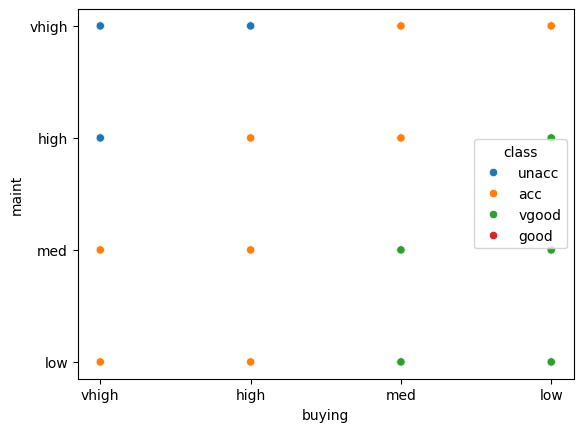

In [19]:
sns.scatterplot(x = df["buying"], y = df["maint"], hue = df["class"])
plt.show()

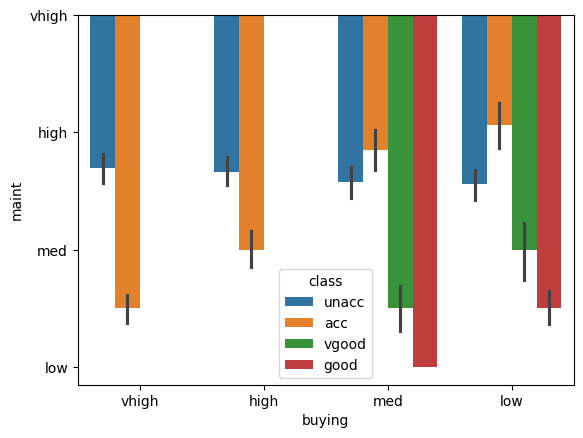

In [20]:
sns.barplot(x = df["buying"], y = df["maint"], hue = df["class"])
plt.show()

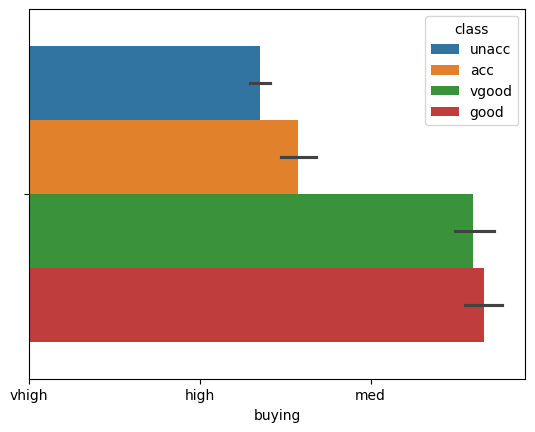

In [21]:
sns.barplot(x = df["buying"], hue = df["class"])
plt.show()

In [22]:
X = df.drop("class", axis = 1)
y = df["class"]

In [23]:
from sklearn.model_selection import train_test_split

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

In [25]:
X_train.shape

(1208, 6)

In [26]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [27]:
df.columns

Index(['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class'], dtype='object')

In [28]:
categorical_cols = ["buying", "maint", "lug_boot", "safety"]
numerical_cols = ["doors", "persons"]

In [29]:
for col in categorical_cols:
    print(df[col].value_counts())

buying
high     432
med      432
low      432
vhigh    431
Name: count, dtype: int64
maint
high     432
med      432
low      432
vhigh    431
Name: count, dtype: int64
lug_boot
med      576
big      576
small    575
Name: count, dtype: int64
safety
med     576
high    576
low     575
Name: count, dtype: int64


In [30]:
ordinal_encoder = OrdinalEncoder(categories = [
    ["low", "med", "high", "vhigh"],
    ["low", "med", "high", "vhigh"],
    ["small", "med", "big"],
    ["low", "med", "high"]
])

In [31]:
preprocessor = ColumnTransformer(transformers = [
    ("doesnt_matter", ordinal_encoder, categorical_cols)
], remainder = "passthrough") 

In [32]:
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

In [33]:
from sklearn.tree import DecisionTreeClassifier

In [34]:
tree_model = DecisionTreeClassifier(criterion = "gini", max_depth = 3)

In [35]:
tree_model.fit(X_train_transformed, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [36]:
y_pred = tree_model.predict(X_test_transformed)

In [37]:
from sklearn.metrics import classification_report, confusion_matrix

In [38]:
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

         acc       0.56      0.56      0.56       118
        good       0.00      0.00      0.00        17
       unacc       0.87      0.97      0.92       361
       vgood       0.00      0.00      0.00        23

    accuracy                           0.80       519
   macro avg       0.36      0.38      0.37       519
weighted avg       0.73      0.80      0.77       519

[[ 66   0  52   0]
 [ 17   0   0   0]
 [ 11   0 350   0]
 [ 23   0   0   0]]


c:\Users\emres\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1706: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\emres\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1706: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\emres\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1706: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

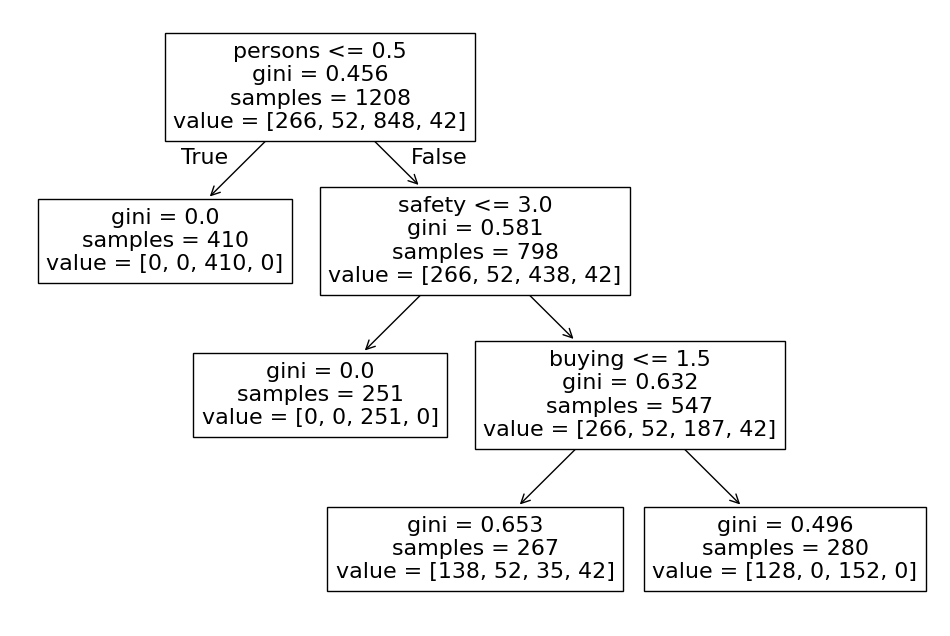

In [39]:
plt.figure(figsize = (12, 8))

from sklearn import tree

tree.plot_tree(tree_model.fit(X_train_transformed, y_train), feature_names = X_train.columns)
plt.show()

In [40]:
params = {
    "criterion" : ["gini", "entropy", "log_loss"],
    "splitter" : ["best", "random"],
    "max_depth" : [1, 2, 3, 4, 5, 15, None],
    "max_features" : ["sqrt", "log2", None]
}

In [41]:
from sklearn.model_selection import GridSearchCV

In [42]:
grid = GridSearchCV(estimator = DecisionTreeClassifier(), param_grid = params, n_jobs = -1, verbose = 1, scoring = "accuracy")

In [43]:
import warnings
warnings.filterwarnings("ignore")

In [44]:
grid.fit(X_train_transformed, y_train)

Fitting 5 folds for each of 126 candidates, totalling 630 fits


,estimator,DecisionTreeClassifier()
,param_grid,"{'criterion': ['gini', 'entropy', ...], 'max_depth': [1, 2, ...], 'max_features': ['sqrt', 'log2', ...], 'splitter': ['best', 'random']}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,None
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'gini'


In [45]:
grid.best_params_

{'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'splitter': 'best'}

In [46]:
y_pred = grid.predict(X_test_transformed)

In [47]:
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

         acc       0.97      0.94      0.95       118
        good       0.78      0.82      0.80        17
       unacc       0.99      1.00      0.99       361
       vgood       0.91      0.87      0.89        23

    accuracy                           0.97       519
   macro avg       0.91      0.91      0.91       519
weighted avg       0.97      0.97      0.97       519

[[111   2   4   1]
 [  2  14   0   1]
 [  1   0 360   0]
 [  1   2   0  20]]


In [48]:
tree_model_new = DecisionTreeClassifier(criterion = "entropy", max_depth = None, max_features = None, splitter = "best")
tree_model_new.fit(X_train_transformed, y_train)
y_pred = tree_model_new.predict(X_test_transformed)
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

         acc       0.94      0.92      0.93       118
        good       0.78      0.82      0.80        17
       unacc       0.98      0.99      0.99       361
       vgood       0.90      0.78      0.84        23

    accuracy                           0.96       519
   macro avg       0.90      0.88      0.89       519
weighted avg       0.96      0.96      0.96       519

[[109   2   6   1]
 [  2  14   0   1]
 [  2   0 359   0]
 [  3   2   0  18]]


[Text(0.609375, 0.9615384615384616, 'persons <= 0.5\nentropy = 1.203\nsamples = 1208\nvalue = [266, 52, 848, 42]'),
 Text(0.5946691176470589, 0.8846153846153846, 'entropy = 0.0\nsamples = 410\nvalue = [0, 0, 410, 0]'),
 Text(0.6020220588235294, 0.9230769230769231, 'True  '),
 Text(0.6240808823529411, 0.8846153846153846, 'safety <= 3.0\nentropy = 1.484\nsamples = 798\nvalue = [266, 52, 438, 42]'),
 Text(0.6167279411764706, 0.9230769230769231, '  False'),
 Text(0.609375, 0.8076923076923077, 'entropy = 0.0\nsamples = 251\nvalue = [0, 0, 251, 0]'),
 Text(0.6387867647058824, 0.8076923076923077, 'buying <= 1.5\nentropy = 1.642\nsamples = 547\nvalue = [266, 52, 187, 42]'),
 Text(0.3952205882352941, 0.7307692307692307, 'maint <= 1.5\nentropy = 1.756\nsamples = 267\nvalue = [138, 52, 35, 42]'),
 Text(0.20955882352941177, 0.6538461538461539, 'persons <= 1.5\nentropy = 1.776\nsamples = 139\nvalue = [45, 52, 7, 35]'),
 Text(0.08823529411764706, 0.5769230769230769, 'doors <= 0.5\nentropy = 1.194\ns

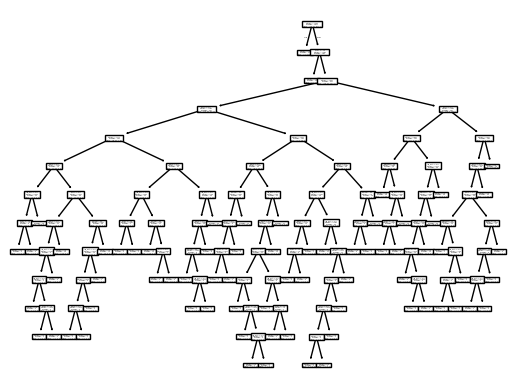

In [49]:
tree.plot_tree(tree_model_new.fit(X_train_transformed, y_train), feature_names = columns)